# Heart Disease Prediction — Exploratory Data Analysis

## MLOps Assignment 01

### Objective
Explore, clean, and prepare the Heart Disease UCI dataset
for downstream machine learning experimentation.

### Analysis Areas
1. Dataset structure
2. Missing-value analysis
3. Duplicate analysis
4. Feature distributions
5. Categorical feature analysis
6. Correlation analysis
7. Target-class balance
8. Data-cleaning decisions

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


### Assigning Feature Names

The raw `processed.cleveland.data` file does not contain column headers.
The accompanying `heart-disease.names` documentation specifies that only
14 attributes are used for the processed Cleveland dataset.

The attributes are retained in the following order:
age, sex, cp, trestbps, chol, fbs, restecg, thalach,
exang, oldpeak, slope, ca, thal, and num.

In [16]:
import pandas as pd

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    "../data/raw/processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [17]:
df.info()
missing_values = df.isnull().sum()

print(missing_values)
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)
print("Duplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
age         0.000000


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [18]:
print("ca value counts:")
print(df["ca"].value_counts(dropna=False))

print("\nthal value counts:")
print(df["thal"].value_counts(dropna=False))

ca value counts:
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

thal value counts:
thal
3.0    166
7.0    117
6.0     18
NaN      2
Name: count, dtype: int64


### Missing Value Handling

The raw Cleveland dataset contains missing values represented by `?`.

After converting `?` to NaN:

- `ca`: 4 missing values (1.32%)
- `thal`: 2 missing values (0.66%)

No duplicate rows were identified.

Since `ca` is a discrete feature representing the number of major vessels,
its missing values will be imputed using the median of the observed values.

Since `thal` is a categorical feature, its missing values will be imputed
using the mode (most frequent category).

The number of missing values is small relative to the total dataset size,
so row deletion was not selected.

In [19]:
df_clean = df.copy()

# Handle missing values
df_clean["ca"] = df_clean["ca"].fillna(df_clean["ca"].median())
df_clean["thal"] = df_clean["thal"].fillna(df_clean["thal"].mode()[0])

print(df_clean.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


In [20]:
print("Target value counts:")
print(df_clean["num"].value_counts().sort_index())
print("Unique target values:")
print(sorted(df_clean["num"].unique()))
df_clean["target"] = (df_clean["num"] > 0).astype(int)

print("Binary target distribution:")
print(df_clean["target"].value_counts().sort_index())

print(pd.crosstab(df_clean["num"], df_clean["target"]))

Target value counts:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
Unique target values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64
target    0   1
num            
0       164   0
1         0  55
2         0  36
3         0  35
4         0  13


## Feature Types and Encoding

The dataset contains both numerical and categorical features.

### Numerical features
- age
- trestbps
- chol
- thalach
- oldpeak

### Categorical/binary features
- sex
- cp
- fbs
- restecg
- exang
- slope
- ca
- thal

The original categorical values are retained in `df_clean` for EDA.
Encoding will be applied when creating the machine-learning-ready dataset.
The original `num` diagnosis is retained for traceability, while `target`
is used as the binary classification target.

In [21]:
categorical_cols = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

for col in categorical_cols:
    print(f"\n{col} value counts:")
    print(df_clean[col].value_counts().sort_index())


sex value counts:
sex
0.0     97
1.0    206
Name: count, dtype: int64

cp value counts:
cp
1.0     23
2.0     50
3.0     86
4.0    144
Name: count, dtype: int64

fbs value counts:
fbs
0.0    258
1.0     45
Name: count, dtype: int64

restecg value counts:
restecg
0.0    151
1.0      4
2.0    148
Name: count, dtype: int64

exang value counts:
exang
0.0    204
1.0     99
Name: count, dtype: int64

slope value counts:
slope
1.0    142
2.0    140
3.0     21
Name: count, dtype: int64

ca value counts:
ca
0.0    180
1.0     65
2.0     38
3.0     20
Name: count, dtype: int64

thal value counts:
thal
3.0    168
6.0     18
7.0    117
Name: count, dtype: int64


Histograms

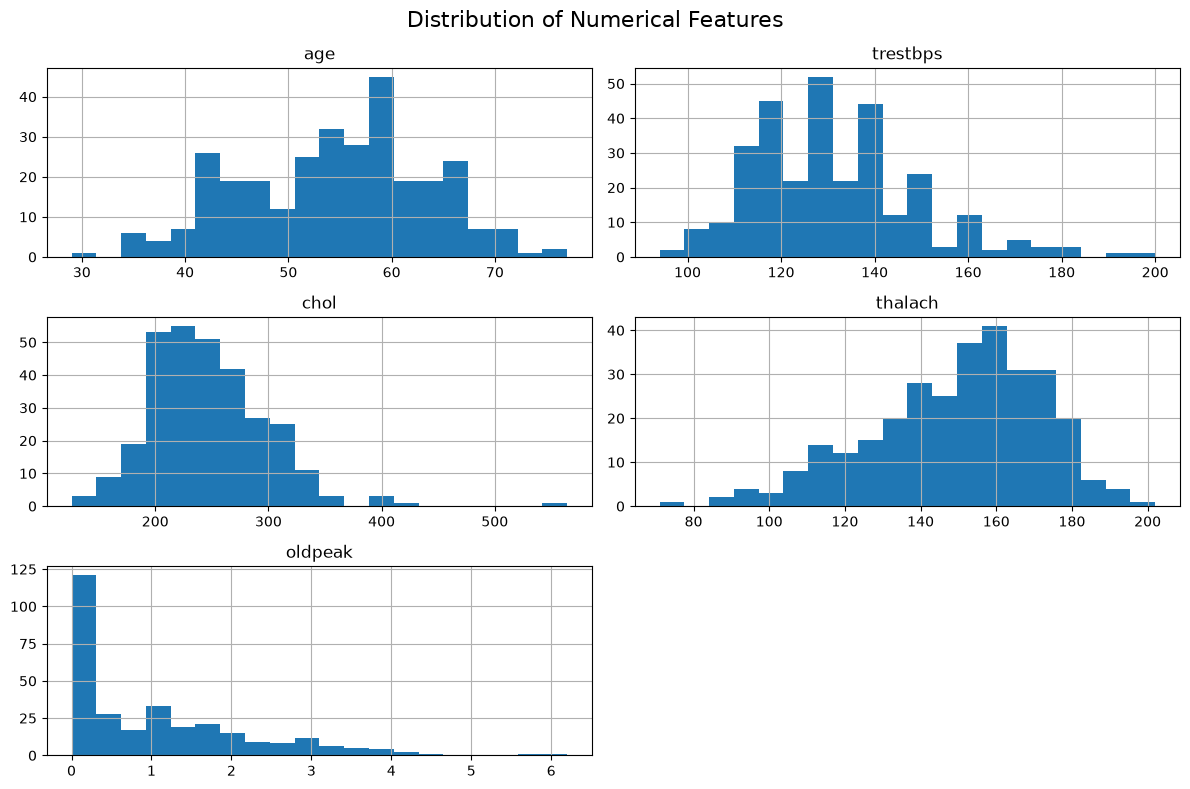

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df_clean[numerical_cols].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### Histogram Findings

- **Age:** The observations are concentrated mainly between approximately 40 and 65 years.
- **Resting blood pressure (`trestbps`):** Most observations fall around 110–150, with a right tail toward higher values.
- **Cholesterol (`chol`):** The distribution is right-skewed, with a small number of substantially higher observations.
- **Maximum heart rate (`thalach`):** Most observations are concentrated approximately between 130 and 180.
- **Oldpeak:** The distribution is strongly right-skewed, with most observations at relatively low values.
- Potentially extreme observations were retained because unusual values were not assumed to be erroneous without supporting evidence.

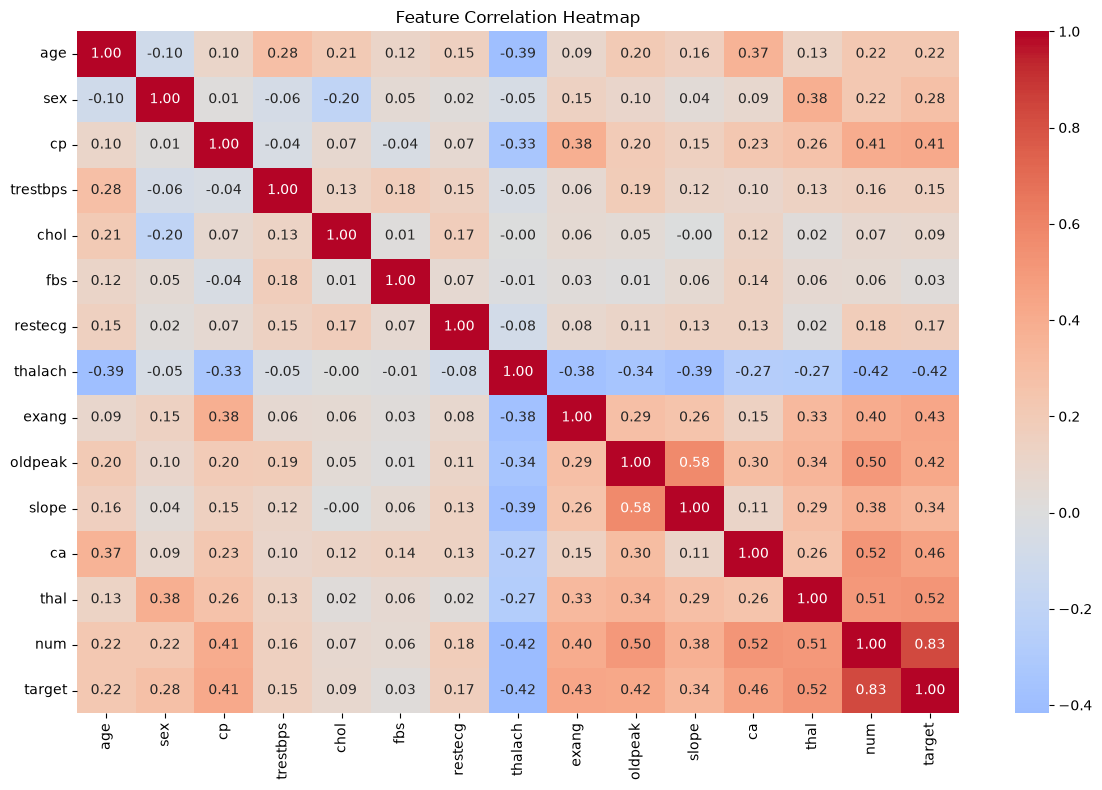

In [23]:
plt.figure(figsize=(12, 8))

correlation_matrix = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### Correlation Analysis Findings

The correlation heatmap shows the linear associations among the dataset
features and the binary target.

The strongest positive associations with the target are observed for
`thal` (0.52), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42), and
`cp` (0.41).

`thalach` shows a negative correlation with the target (-0.42).

Some relationships also exist between individual predictors, such as
`oldpeak` and `slope` (0.58).

Correlation represents association and does not imply causation.

The original `num` attribute is strongly correlated with `target` because
the binary target was derived from `num`. Therefore, `num` will not be
used as an input feature during model training to avoid target leakage.

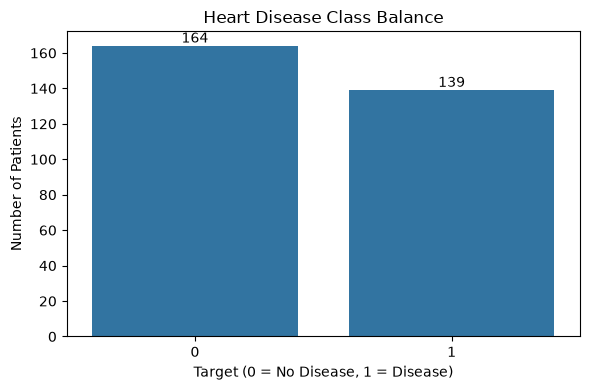

In [24]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    data=df_clean,
    x="target"
)

plt.title("Heart Disease Class Balance")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Class Balance Findings

The binary target contains 164 observations for class 0 (no disease)
and 139 observations for class 1 (disease).

This corresponds to approximately 54.13% and 45.87%, respectively.
The two classes are relatively close in size, so there is no severe class
imbalance in the dataset based on the observed class distribution.

## Feature Encoding

The cleaned dataset contains numerical, binary, categorical, and discrete
features.

- Numerical features: `age`, `trestbps`, `chol`, `thalach`, `oldpeak`
- Binary features: `sex`, `fbs`, `exang`
- Categorical features: `cp`, `restecg`, `thal`
- Discrete/ordinal features: `slope`, `ca`

Nominal categorical features are one-hot encoded to avoid introducing an
artificial numerical ordering. Binary features are retained as 0/1.

In [25]:
df_model = df_clean.copy()
df_model = df_model.drop(columns=["num"])
categorical_cols = ["cp", "restecg", "thal"]

df_model = pd.get_dummies(
    df_model,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)
print("Shape after encoding:", df_model.shape)

print("\nColumns:")
print(df_model.columns.tolist())

# print("\nData types:")
# print(df_model.dtypes)
print("\nMissing values:")
print(df_model.isnull().sum().sum())

integer_cols = [
    "sex",
    "fbs",
    "exang",
    "slope",
    "ca"
]

df_model[integer_cols] = df_model[integer_cols].astype(int)

print(df_model.dtypes)

Shape after encoding: (303, 21)

Columns:
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'target', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']

Missing values:
0
age            float64
sex              int64
trestbps       float64
chol           float64
fbs              int64
thalach        float64
exang            int64
oldpeak        float64
slope            int64
ca               int64
target           int64
cp_1.0           int64
cp_2.0           int64
cp_3.0           int64
cp_4.0           int64
restecg_0.0      int64
restecg_1.0      int64
restecg_2.0      int64
thal_3.0         int64
thal_6.0         int64
thal_7.0         int64
dtype: object


In [26]:
from pathlib import Path

output_dir = Path("../data/preprocessed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "heart_disease_processed.csv"

df_model.to_csv(output_path, index=False)

print(f"Processed dataset saved to: {output_path}")
print(pd.read_csv(output_path).shape)

Processed dataset saved to: ../data/preprocessed/heart_disease_processed.csv
(303, 21)


## Final Dataset Validation

The final preprocessed dataset was validated after missing-value handling
and categorical feature encoding.

The validation confirms:

- 303 observations
- 21 columns
- No missing values
- No duplicate records
- Binary target variable available
- Original `num` attribute removed to prevent target leakage

The processed dataset is saved as:

`data/preprocessed/heart_disease_processed.csv`

In [27]:
print("Final dataset shape:", df_model.shape)
print("Total missing values:", df_model.isnull().sum().sum())
print("Duplicate records:", df_model.duplicated().sum())
print("Target distribution:")
print(df_model["target"].value_counts())

Final dataset shape: (303, 21)
Total missing values: 0
Duplicate records: 0
Target distribution:
target
0    164
1    139
Name: count, dtype: int64


## Categorical Feature Analysis

The dataset contains categorical features that describe different
clinical characteristics.

- `cp`: Chest pain type
- `restecg`: Resting electrocardiographic results
- `thal`: Thalassemia category

The frequency of each category is visualized to understand the
distribution of categorical observations.

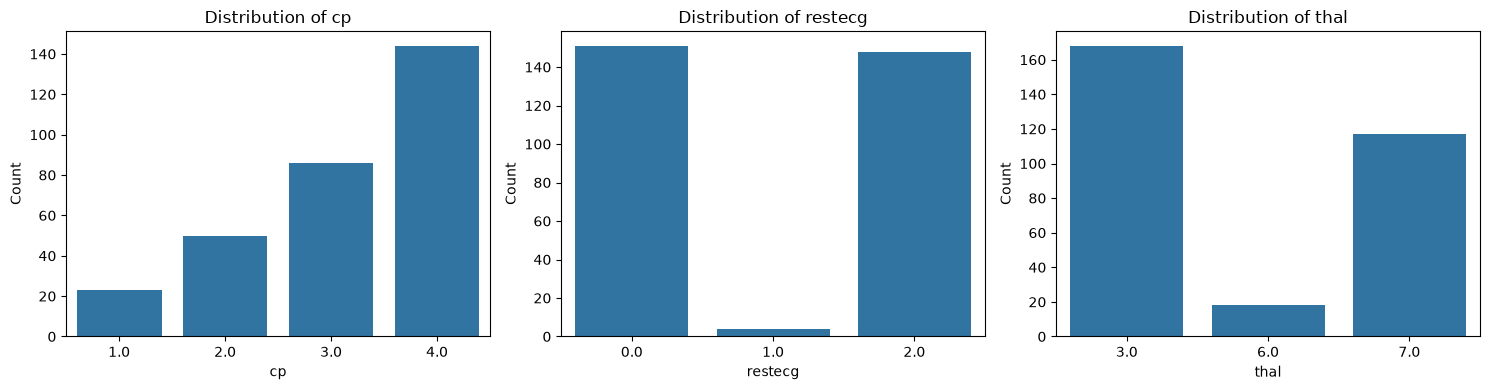

In [28]:
categorical_cols = ["cp", "restecg", "thal"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=df_clean, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

### Categorical Feature Findings

- **Chest pain (`cp`):** Category 4 is the most frequent, followed by category 3. Categories 1 and 2 occur less frequently.
- **Resting ECG (`restecg`):** Categories 0 and 2 are the dominant categories, while category 1 occurs infrequently.
- **Thalassemia (`thal`):** Category 3 is the most frequent, followed by category 7. Category 6 is relatively uncommon.

The categorical distributions show that some categories occur much more frequently
than others. These categorical features are therefore encoded using one-hot
encoding before downstream machine learning experimentation.